<a href="https://colab.research.google.com/github/Tamarakira/Software-Artefact-with-Documentation/blob/main/Data_Science_Week_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

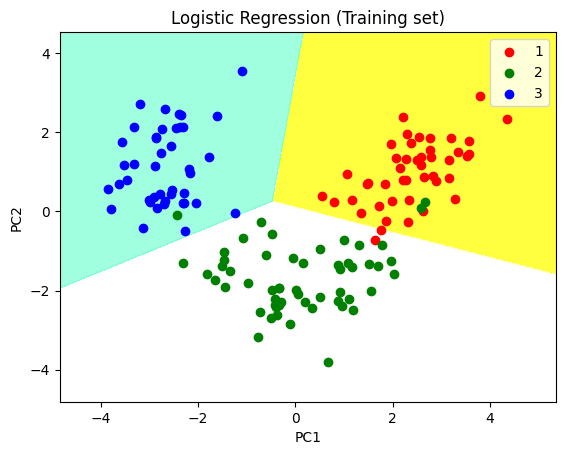

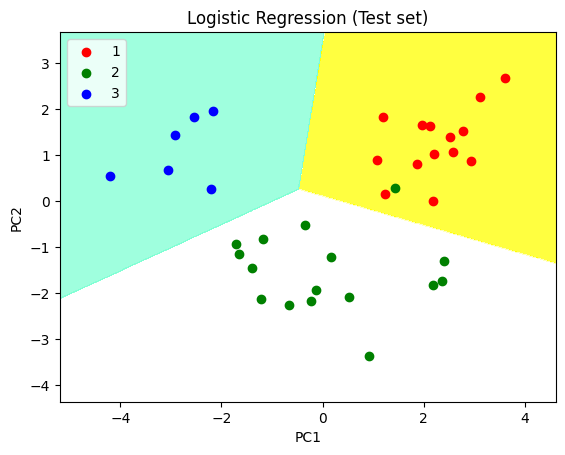

/tmp/ipykernel_1765/4180024180.py:117: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


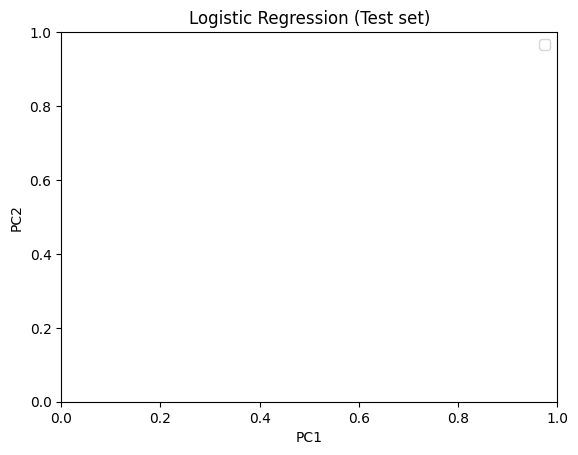

In [16]:
# Importing required libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Importing the dataset
dataset = pd.read_excel('Wine.xlsx')

# Splitting the dataset into X and y
X = dataset.iloc[:, 0:13].values
y = dataset.iloc[:, 13].values

# Spliting the dataset into the Training set and Test set
# Splitting the X and Y into the
# Training set and Testing set
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=0)

# Doing the pre-processing part on training and testing set such as fitting the Standard scale preforming preprocessing part
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# Applying the PCA function into the training and testing set for analysis
# Applying PCA function on training and testing set of X component
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)
# explained_variance = pca.explained_variance_ratio_

#Fitting Logistic Regression To the training set
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state=0)
classifier.fit(X_train, y_train)

#Predicting the test set result using predict function under LogisticRegression
y_pred = classifier.predict(X_test)

# Making confusion matrix between test set of Y and oredicted value
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

# Predicting the training set result through scatter plot
# Predicting the training set result through scatter plot
from matplotlib.colors import ListedColormap
X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(
    np.arange(start=X_set[:, 0].min() - 1,
              stop=X_set[:, 0].max() + 1, step=0.01),
    np.arange(start=X_set[:, 1].min() - 1,
              stop=X_set[:, 1].max() + 1, step=0.01)
)
plt.contourf(
    X1, X2,
    classifier.predict(
        np.array([X1.ravel(), X2.ravel()]).T
    ).reshape(X1.shape),
    alpha=0.75,
    cmap=ListedColormap(['yellow', 'white', 'aquamarine'])
)
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(
        X_set[y_set == j, 0],
        X_set[y_set == j, 1],
        color=ListedColormap(['red', 'green', 'blue'])(i),
        label=j
    )
plt.title('Logistic Regression (Training set)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

# Show scatter plot
plt.show()

# Visualising the Test set results through scatter plot
X_set, y_set = X_test, y_test
X1, X2 = np.meshgrid(
    np.arange(X_set[:, 0].min() - 1,
              X_set[:, 0].max() + 1, 0.01),
    np.arange(X_set[:, 1].min() - 1,
              X_set[:, 1].max() + 1, 0.01)
)
plt.contourf(
    X1, X2,
    classifier.predict(
        np.array([X1.ravel(), X2.ravel()]).T
    ).reshape(X1.shape),
    alpha=0.75,
    cmap=ListedColormap(['yellow', 'white', 'aquamarine'])
)
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
    plt.scatter(
        X_set[y_set == j, 0],
        X_set[y_set == j, 1],
        color=ListedColormap(['red', 'green', 'blue'])(i),
        label=j
    )
plt.title('Logistic Regression (Test set)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

# Title for Scatter plot
plt.title('Logistic Regression (Test set)')
plt.xlabel('PC1')  # for Xlabel​
plt.ylabel('PC2')  # for Ylabel​
plt.legend()
plt.show()